# House Prices - V3: Selected Prediction Model

**Goal:** produce a ready-to-submit prediction file using the strongest blend found in the current local experiments.

- Search results cover 69 model/preprocessing candidates, including Ridge, ElasticNet, SVR, Gradient Boosting, XGBoost, and CatBoost. The complete record is in `v3_experiments/`.
- Improve missing-facility handling, use neighborhood medians for LotFrontage, express quality grades in order, and add size/age/facility features with a few explicit interactions.
- For SVR, cap continuous feature values at training-fold 99th percentiles to limit extreme leverage. No training or validation rows are removed. XGBoost and CatBoost retain an uncapped view.
- Selected blend: **50% SVR + 10% XGBoost + 40% CatBoost**, using natural-log price predictions. Weights were selected on a coarse 0.1 grid, with no negative weights or stacking.
- Five-fold OOF selection score: approximately **0.117973**, compared with V2's **0.127864** under the same seed-42 folds. Preprocessing statistics are fitted only on training folds. An additional seed-2026 stability check is saved in `v3_experiments/stability_check.csv`.
- Model and weight selection reuse OOF results, so the selection score may be optimistic. The second seed is a stability check, not an untouched test set. Only Kaggle can determine the actual leaderboard score.
- Train on all 1,460 labeled rows and predict all 1,459 test rows. Save `submission_v3.csv` without rounding, tail adjustments, or using test labels.

Use Python 3.11-3.13 and `requirements-v3.txt`. Run all cells in order. Runtime numerical warnings are treated as errors rather than hidden.


In [1]:
from pathlib import Path
from time import perf_counter
import hashlib, json, warnings, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from threadpoolctl import threadpool_limits

warnings.filterwarnings("error", category=RuntimeWarning)


Matplotlib is building the font cache; this may take a moment.


In [2]:
data_dir = Path("Dataset")
if not data_dir.exists():
    data_dir = Path("Proj/Dataset")
if not data_dir.exists():
    data_dir = Path("/kaggle/input/house-prices-advanced-regression-techniques")

train = pd.read_csv(data_dir / "train.csv", keep_default_na=False, na_values=["", "NA"])
test = pd.read_csv(data_dir / "test.csv", keep_default_na=False, na_values=["", "NA"])
y = np.log(train["SalePrice"].to_numpy())
print("Train:", train.shape, "Test:", test.shape)


Train: (1460, 81) Test: (1459, 80)


In [3]:
def make_features(frame):
    d=frame.copy()
    for c in ['YearBuilt','YearRemodAdd','GarageYrBlt']:
        d.loc[(d[c]<1800)|(d[c]>d.YrSold+1),c]=np.nan
    no_basement=d.TotalBsmtSF.eq(0)
    no_garage=d.GarageCars.eq(0)&d.GarageArea.eq(0)
    absence={'Alley':pd.Series(True,index=d.index),'Fence':pd.Series(True,index=d.index),
             'MiscFeature':d.MiscVal.eq(0),'PoolQC':d.PoolArea.eq(0),
             'FireplaceQu':d.Fireplaces.eq(0),'MasVnrType':d.MasVnrArea.eq(0)}
    for c in ['BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2']:
        absence[c]=no_basement
    for c in ['GarageType','GarageFinish','GarageQual','GarageCond']:
        absence[c]=no_garage
    for c,mask in absence.items():
        d.loc[mask&d[c].isna(),c]='None'
    for c in ['BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','BsmtFullBath','BsmtHalfBath']:
        d.loc[no_basement&d[c].isna(),c]=0
    d.loc[d.MasVnrType.eq('None')&d.MasVnrArea.isna(),'MasVnrArea']=0
    for c in ['MSSubClass','MoSold']:
        d[c]=d[c].astype(str)
    d['HouseAge']=(d.YrSold-d.YearBuilt).clip(lower=0)
    d['RemodelAge']=(d.YrSold-d.YearRemodAdd).clip(lower=0)
    d['GarageAge']=(d.YrSold-d.GarageYrBlt).clip(lower=0)
    d.loc[no_garage,'GarageAge']=0
    d=d.drop(columns='GarageYrBlt')
    d['TotalSF']=d.TotalBsmtSF+d['1stFlrSF']+d['2ndFlrSF']
    d['FinishedSF']=d.GrLivArea+d.BsmtFinSF1+d.BsmtFinSF2
    d['TotalBath']=d.FullBath+.5*d.HalfBath+d.BsmtFullBath+.5*d.BsmtHalfBath
    d['TotalOutdoorSF']=d.WoodDeckSF+d.OpenPorchSF+d.EnclosedPorch+d['3SsnPorch']+d.ScreenPorch
    for source,name in [('GarageArea','HasGarage'),('TotalBsmtSF','HasBasement'),
                        ('Fireplaces','HasFireplace'),('PoolArea','HasPool'),('2ndFlrSF','HasSecondFloor')]:
        d[name]=np.where(d[source].isna(),np.nan,d[source].gt(0).astype(float))
    d['WasRemodeled']=(d.YearRemodAdd!=d.YearBuilt).astype(int)
    d['IsNew']=(d.YearBuilt>=d.YrSold).astype(int)
    quality={'None':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5}
    for c in ['ExterQual','ExterCond','BsmtQual','BsmtCond','HeatingQC','KitchenQual','FireplaceQu','GarageQual','GarageCond','PoolQC']:
        d[c]=d[c].map(quality)
    d['BsmtExposure']=d.BsmtExposure.map({'None':0,'No':0,'Mn':1,'Av':2,'Gd':3})
    d['GarageFinish']=d.GarageFinish.map({'None':0,'Unf':1,'RFn':2,'Fin':3})
    for c in ['BsmtFinType1','BsmtFinType2']:
        d[c]=d[c].map({'None':0,'Unf':1,'LwQ':2,'Rec':3,'BLQ':4,'ALQ':5,'GLQ':6})
    # A few explicit interactions, without generating all feature pairs.
    d['QualityLivingArea']=d.OverallQual*np.log1p(d.GrLivArea)
    d['QualityTotalArea']=d.OverallQual*np.log1p(d.TotalSF)
    d['QualityHouseAge']=d.OverallQual*d.HouseAge
    d['TotalQuality']=d.OverallQual+d.OverallCond
    return d


In [4]:
def prepare(a,b,scale='standard',advanced_mode=True,clip=False):
    a=a.copy();b=b.copy()
    if advanced_mode:
        frontage=a.groupby('Neighborhood').LotFrontage.median()
        global_frontage=a.LotFrontage.median()
        for d in [a,b]:
            d['LotFrontage']=d.LotFrontage.fillna(d.Neighborhood.map(frontage)).fillna(global_frontage)
        for c in a.select_dtypes(include='object'):
            a[c]=a[c].fillna('Unknown');b[c]=b[c].fillna('Unknown')
            common=a[c].value_counts(); keep=common[common>=3].index
            a[c]=a[c].where(a[c].isin(keep),'Other')
            b[c]=b[c].where(b[c].isin(keep),'Other')
        excluded={'YearBuilt','YearRemodAdd','YrSold','OverallQual','OverallCond','QualityLivingArea','QualityTotalArea','QualityHouseAge','TotalQuality'}
        log_cols=[c for c in a.select_dtypes(include=np.number) if c not in excluded and a[c].nunique()>10 and a[c].min()>=0 and a[c].skew()>.75]
        for c in log_cols:
            a[c]=np.log1p(a[c]);b[c]=np.log1p(b[c])
    if clip:
        for c in a.select_dtypes(include=np.number):
            if a[c].nunique()>20 and c not in ['YearBuilt','YearRemodAdd','YrSold']:
                upper=a[c].quantile(.995 if clip is True else clip)
                a[c]=a[c].clip(upper=upper);b[c]=b[c].clip(upper=upper)
    medians=a.median(numeric_only=True)
    modes=a.select_dtypes(include='object').mode().iloc[0]
    a=a.fillna(medians).fillna(modes).fillna(0)
    b=b.fillna(medians).fillna(modes).fillna(0)
    a=pd.get_dummies(a,dtype=float)
    b=pd.get_dummies(b,dtype=float).reindex(columns=a.columns,fill_value=0)
    a=a.to_numpy(dtype=np.float64);b=b.to_numpy(dtype=np.float64)
    scaler=StandardScaler() if scale=='standard' else RobustScaler()
    sa=scaler.fit_transform(a);sb=scaler.transform(b)
    assert all(np.isfinite(x).all() for x in [a,b,sa,sb])
    return a,b,sa,sb


def prepare_native(a, b):
    a = a.copy()
    b = b.copy()
    frontage = a.groupby("Neighborhood").LotFrontage.median()
    global_frontage = a.LotFrontage.median()
    for frame in [a, b]:
        frame["LotFrontage"] = frame.LotFrontage.fillna(frame.Neighborhood.map(frontage)).fillna(global_frontage)
        for col in frame.select_dtypes(include="object"):
            frame[col] = frame[col].fillna("Unknown").astype(str)
    return a, b, a.select_dtypes(include="object").columns.tolist()


def build_model(spec):
    if spec["family"] == "svr":
        return SVR(**spec["params"])
    if spec["family"] == "xgb":
        return XGBRegressor(**spec["params"], tree_method="hist", objective="reg:squarederror", n_jobs=4, random_state=42)
    return CatBoostRegressor(**spec["params"])


In [5]:
model_specs = [{'name': 'svr_advanced_clip99_c10_g0.0001', 'family': 'svr', 'params': {'C': 10, 'gamma': 0.0001, 'epsilon': 0.01}, 'prep': 'advanced_clip99', 'scale': 'standard', 'weight': 0.5}, {'name': 'xgb_d3_n2000', 'family': 'xgb', 'params': {'n_estimators': 2000, 'learning_rate': 0.025, 'max_depth': 3, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.7, 'reg_lambda': 3, 'reg_alpha': 0.01}, 'prep': 'advanced', 'scale': 'standard', 'weight': 0.1}, {'name': 'cat_d6_l5', 'family': 'cat', 'prep': 'advanced_native', 'scale': 'none', 'params': {'iterations': 1800, 'depth': 6, 'learning_rate': 0.03, 'l2_leaf_reg': 5, 'loss_function': 'RMSE', 'random_seed': 42, 'thread_count': 4, 'verbose': False, 'allow_writing_files': False}, 'weight': 0.4}]

assert abs(sum(s["weight"] for s in model_specs) - 1) < 1e-12
X = make_features(train.drop(columns=["Id", "SalePrice"]))
X_test = make_features(test.drop(columns="Id"))


In [6]:
oof_predictions = {}
fold_records = []
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

for spec in model_specs:
    oof = np.zeros(len(train))
    start = perf_counter()
    for fold, (tr, va) in enumerate(kfold.split(X), start=1):
        model = build_model(spec)
        if spec["family"] == "cat":
            a, b, cat_columns = prepare_native(X.iloc[tr], X.iloc[va])
            model.fit(a, y[tr], cat_features=cat_columns)
            oof[va] = model.predict(b)
        else:
            a, b, scaled_a, scaled_b = prepare(
                X.iloc[tr], X.iloc[va], scale=spec["scale"],
                clip=0.99 if "clip99" in spec["prep"] else False
            )
            with threadpool_limits(limits=1):
                model.fit(scaled_a if spec["family"] == "svr" else a, y[tr])
                oof[va] = model.predict(scaled_b if spec["family"] == "svr" else b)
        assert np.isfinite(oof[va]).all()
        fold_records.append({"Model": spec["family"], "Fold": fold,
                             "log-RMSE": np.sqrt(mean_squared_error(y[va], oof[va]))})
        print(spec["family"], "completed fold", fold)
    oof_predictions[spec["family"]] = oof
    print(f"{spec['family']} OOF log-RMSE: {np.sqrt(mean_squared_error(y, oof)):.6f}; seconds: {perf_counter()-start:.1f}")

blend_oof = sum(s["weight"] * oof_predictions[s["family"]] for s in model_specs)
blend_score = np.sqrt(mean_squared_error(y, blend_oof))
print(f"V3 blend OOF log-RMSE: {blend_score:.6f}")


svr completed fold 1
svr completed fold 2


svr completed fold 3
svr completed fold 4


svr completed fold 5
svr OOF log-RMSE: 0.121497; seconds: 0.8


xgb completed fold 1


xgb completed fold 2


xgb completed fold 3


... (3 outputs left out)

cat completed fold 2


cat completed fold 3


cat completed fold 4


cat completed fold 5
cat OOF log-RMSE: 0.123452; seconds: 46.3
V3 blend OOF log-RMSE: 0.117973


   Model  OOF log-RMSE  Fold mean  Fold standard deviation
V3 blend      0.117973   0.117102                 0.016002
     svr      0.121497   0.120911                 0.013327
     cat      0.123452   0.122471                 0.017360
     xgb      0.126523   0.125117                 0.021032


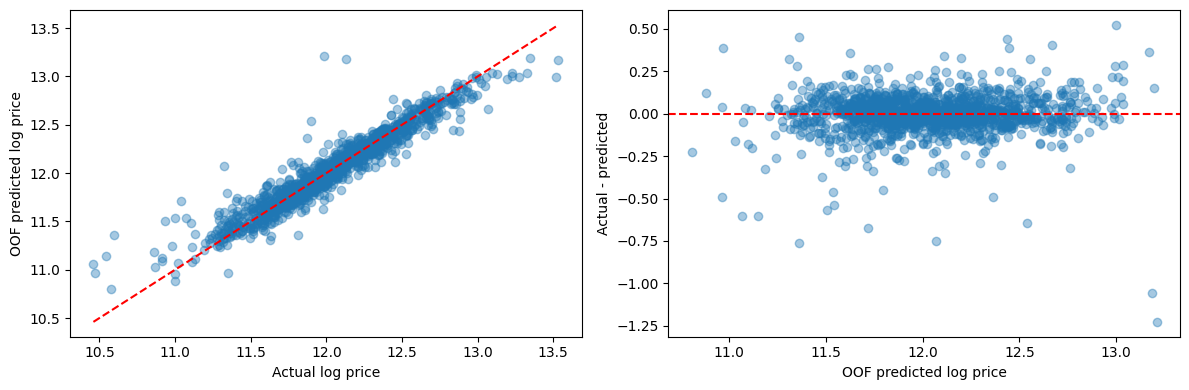

In [7]:
summary = []
for name, pred in {**oof_predictions, "V3 blend": blend_oof}.items():
    fold_scores = [np.sqrt(mean_squared_error(y[va], pred[va])) for _, va in kfold.split(X)]
    summary.append({"Model": name, "OOF log-RMSE": np.sqrt(mean_squared_error(y, pred)),
                    "Fold mean": np.mean(fold_scores), "Fold standard deviation": np.std(fold_scores, ddof=1)})
summary = pd.DataFrame(summary).sort_values("OOF log-RMSE")
print(summary.round(6).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y, blend_oof, alpha=0.4)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[0].set(xlabel="Actual log price", ylabel="OOF predicted log price")
axes[1].scatter(blend_oof, y - blend_oof, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="OOF predicted log price", ylabel="Actual - predicted")
plt.tight_layout()
plt.show()


In [8]:
test_predictions = {}
for spec in model_specs:
    model = build_model(spec)
    if spec["family"] == "cat":
        a, b, cat_columns = prepare_native(X, X_test)
        model.fit(a, y, cat_features=cat_columns)
        pred = model.predict(b)
    else:
        a, b, scaled_a, scaled_b = prepare(
            X, X_test, scale=spec["scale"],
            clip=0.99 if "clip99" in spec["prep"] else False
        )
        with threadpool_limits(limits=1):
            model.fit(scaled_a if spec["family"] == "svr" else a, y)
            pred = model.predict(scaled_b if spec["family"] == "svr" else b)
    assert np.isfinite(pred).all()
    test_predictions[spec["family"]] = pred
    print("Full-data fit completed:", spec["family"])

test_pred_log = sum(s["weight"] * test_predictions[s["family"]] for s in model_specs)


Full-data fit completed: svr


Full-data fit completed: xgb


Full-data fit completed: cat


In [9]:
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": np.exp(test_pred_log)})
assert submission.columns.tolist() == ["Id", "SalePrice"]
assert len(submission) == 1459 and submission["Id"].is_unique
assert np.array_equal(submission["Id"], test["Id"])
assert np.isfinite(submission["SalePrice"]).all() and (submission["SalePrice"] > 0).all()
if (data_dir / "sample_submission.csv").exists():
    sample = pd.read_csv(data_dir / "sample_submission.csv")
    assert np.array_equal(submission["Id"], sample["Id"])

submission.to_csv("submission_v3.csv", index=False)
summary.to_csv("model_comparison_v3.csv", index=False)
pd.DataFrame(fold_records).to_csv("cv_results_v3.csv", index=False)
pd.DataFrame({"Id": train["Id"], "Actual price": train["SalePrice"],
              "Blend predicted price": np.exp(blend_oof),
              "Absolute log error": np.abs(y - blend_oof)}).to_csv("oof_predictions_v3.csv", index=False)
versions = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "catboost"]}
manifest = {"model_specs": model_specs, "cv_seed": 42, "cv_folds": 5,
            "oof_log_rmse": float(blend_score), "training_rows": len(train), "test_rows": len(test),
            "versions": versions, "train_sha256": hashlib.sha256((data_dir / "train.csv").read_bytes()).hexdigest(),
            "test_sha256": hashlib.sha256((data_dir / "test.csv").read_bytes()).hexdigest()}
Path("run_manifest_v3.json").write_text(json.dumps(manifest, indent=2))

print("READY TO SUBMIT:", Path("submission_v3.csv").resolve())
print(f"Five-fold selection OOF log-RMSE: {blend_score:.6f}")
print("Rows:", len(submission), "Missing values:", submission.isna().sum().sum())
print(submission.head().to_string(index=False))


READY TO SUBMIT: /Users/songxiajinzhi/Desktop/DSAI4204/Proj/submission_v3.csv
Five-fold selection OOF log-RMSE: 0.117973
Rows: 1459 Missing values: 0
  Id     SalePrice
1461 121187.070456
1462 164627.106001
1463 185616.269482
1464 196372.907703
1465 191511.392846
